# Práctica: Bit Rate Control

### Experimento 1. Which data-ordering performs better?
**Enunciado:** Determine empirically which ordering of the chunk data is the most efficient from a lossless data compression point of view (the smaller the bit-rates, the higher the compression). Use the audio sequence you want. Notice that using different audio files you could obtain different results.

#### Comando de instalación de librerías
```pip install soundfile librosa matplotlib numpy```

### Código del experimento

In [1]:
import os
import csv
import zlib
import numpy as np
import librosa

AUDIO_FILES = [
    "./data/FrancoBattiato_LombraDellaLuce.oga",
    "./data/Metallica_Orion.mp3",
    "./data/VVV_InviernoNuclear.oga"
]

CHUNK_SIZE = 1024  # Muestras por chunk (por canal)
MAX_DURATION = 30.0  # Límite exacto de 30 segundos
CSV_FILENAME = "resultados_ejercicio1.csv"

# Preparamos el archivo CSV
with open(CSV_FILENAME, mode='w', newline='', encoding='utf-8') as csv_file:
    writer = csv.writer(csv_file)
    writer.writerow([
        "Cancion", 
        "Duracion_Procesada_sec", 
        "Raw_Bytes", "Raw_Bitrate_kbps", 
        "Serial_Bytes", "Serial_Bitrate_kbps", 
        "Byteplanes2_Bytes", "Byteplanes2_Bitrate_kbps",
        "Mejor_Metodo"
    ])

print("=" * 70)
print(" PROCESANDO EJERCICIO 1 (PRIMEROS 30 SEGUNDOS POR CANCIÓN)")
print("=" * 70)

for file_path in AUDIO_FILES:
    if not os.path.exists(file_path):
        print(f"⚠️ Archivo no encontrado: {file_path}. Saltando...")
        continue
        
    print(f"Procesando (30s): {file_path}...")
    
    # Cargar ÚNICAMENTE los primeros 30 segundos del audio
    audio_signal, sr = librosa.load(file_path, sr=None, mono=False, duration=MAX_DURATION)
    
    if audio_signal.ndim == 1:
        audio_signal = np.vstack([audio_signal, audio_signal])

    pcm_data = (audio_signal * 32767).astype(np.int16).T
    total_samples = len(pcm_data)
    duration_sec = total_samples / sr
    num_chunks = total_samples // CHUNK_SIZE

    bytes_raw = 0
    bytes_serial = 0
    bytes_byteplanes2 = 0

    for i in range(num_chunks):
        chunk = pcm_data[i * CHUNK_SIZE : (i + 1) * CHUNK_SIZE]
        
        # 1. DEFLATE_raw
        raw_b = chunk.tobytes()
        bytes_raw += len(zlib.compress(raw_b))
        
        # 2. DEFLATE_serial
        left_ch = chunk[:, 0]
        right_ch = chunk[:, 1]
        serial_b = left_ch.tobytes() + right_ch.tobytes()
        bytes_serial += len(zlib.compress(serial_b))
        
        # 3. DEFLATE_byteplanes2
        arr_uint8 = np.frombuffer(serial_b, dtype=np.uint8)
        lsb = arr_uint8[0::2].tobytes()
        msb = arr_uint8[1::2].tobytes()
        bytes_byteplanes2 += len(zlib.compress(msb)) + len(zlib.compress(lsb))

    # Bit-rates en kbps
    bitrate_raw = (bytes_raw * 8) / duration_sec / 1000
    bitrate_serial = (bytes_serial * 8) / duration_sec / 1000
    bitrate_byteplanes2 = (bytes_byteplanes2 * 8) / duration_sec / 1000

    results_map = {
        "DEFLATE_raw": bitrate_raw,
        "DEFLATE_serial": bitrate_serial,
        "DEFLATE_byteplanes2": bitrate_byteplanes2
    }
    best_method = min(results_map, key=results_map.get)

    # Guardar en CSV
    with open(CSV_FILENAME, mode='a', newline='', encoding='utf-8') as csv_file:
        writer = csv.writer(csv_file)
        writer.writerow([
            file_path,
            round(duration_sec, 2),
            bytes_raw, round(bitrate_raw, 2),
            bytes_serial, round(bitrate_serial, 2),
            bytes_byteplanes2, round(bitrate_byteplanes2, 2),
            best_method
        ])

print("\n" + "=" * 70)
print(f"¡Proceso completado! Archivo de salida: '{CSV_FILENAME}'.")
print("=" * 70)

 PROCESANDO EJERCICIO 1 (PRIMEROS 30 SEGUNDOS POR CANCIÓN)
Procesando (30s): ./data/FrancoBattiato_LombraDellaLuce.oga...
Procesando (30s): ./data/Metallica_Orion.mp3...
Procesando (30s): ./data/VVV_InviernoNuclear.oga...

¡Proceso completado! Archivo de salida: 'resultados_ejercicio1.csv'.


**¿Qué hemos hecho?:** Hemos probado los primeros 30 segundos de 3 canciones distintas (FrancoBattiato_LombraDellaLuce.oga, Metallica_Orion.mp3 y VVV_InviernoNuclear.oga) para ver qué forma de organizar los datos del audio comprime mejor con DEFLATE.   

**Resultados:** Los datos procesados se guardan automáticamente en resultados_ejercicio1.csv. En las tres canciones analizadas, el algoritmo ``DEFLATE_byteplanes2`` resulta ser el más eficaz, logrando las mayores reducciones en el bit-rate transmitido. Frente al envío sin procesar (``DEFLATE_raw``), la separación en dos planos de bytes (MSB y LSB) consigue ahorrar aproximadamente entre 240 y 340 kbps según el tema.

### Experimento 2. Which BR control algorithm shows the best RD (Rate/Distortion) curve?
**Enunciado:** Considering the RMSE (Root Mean Square Error) as a distortion measure between the sent and the received audio signal, for a concrete audio sequence, generate the RD curve considering a set of different simulated transmission environments (use tc or a any other similar tool). Remember that the X-axis must express bit-rate and the Y-axis, distortion.

### Código del experimento

Simulando BR Control (30s) para: ./data/FrancoBattiato_LombraDellaLuce.oga...
Simulando BR Control (30s) para: ./data/Metallica_Orion.mp3...
Simulando BR Control (30s) para: ./data/VVV_InviernoNuclear.oga...


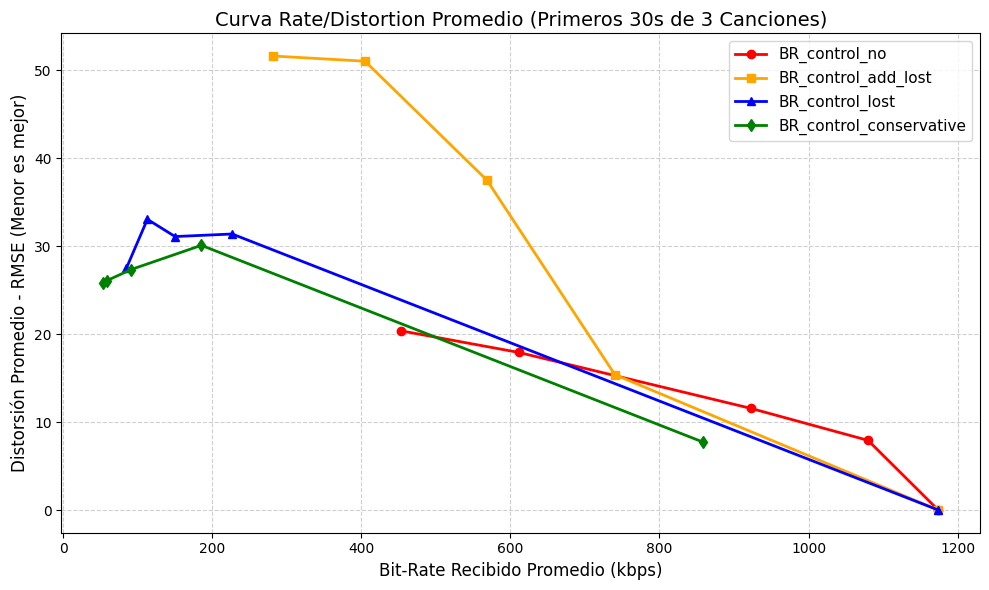

In [ ]:
import os
import zlib
import numpy as np
import librosa
import matplotlib.pyplot as plt

# ==============================================================================
# 0. CONFIGURACIÓN Y LISTA DE CANCIONES (PRIMEROS 30 SEGUNDOS)
# ==============================================================================
AUDIO_FILES = [
    "/data/FrancoBattiato_LombraDellaLuce.oga",
    "/data/Metallica_Orion.mp3",
    "/data/VVV_InviernoNuclear.oga"
]

CHUNK_SIZE = 1024
MAX_DURATION = 30.0  # Procesar solo los primeros 30 segundos
MAX_DELTA = 32767    # Límite superior para delta (int16 PCM)

# ==============================================================================
# FUNCIONES DE CUANTIFICACIÓN Y DECUANTIFICACIÓN OFICIALES (DEAD-ZONE SQ)
# ==============================================================================
def quantize(chunk, delta):
    if delta <= 1:
        return chunk
    chunk_int32 = chunk.astype(np.int32)
    q_chunk = np.sign(chunk_int32) * (np.abs(chunk_int32) // delta)
    return q_chunk.astype(np.int16)

def dequantize(q_chunk, delta):
    if delta <= 1:
        return q_chunk
    q_int32 = q_chunk.astype(np.int32)
    deq = np.clip(q_int32 * delta, -32768, 32767)
    return deq.astype(np.int16)

# ==============================================================================
# LÓGICA DE ACTUALIZACIÓN DE DELTA SEGÚN LAS CLASES DEL REPOSITOIO BR_control*.py
# ==============================================================================
def update_delta(algo_name, current_delta, n_lost):
    if algo_name == "BR_control_no":
        new_delta = current_delta
        
    elif algo_name == "BR_control_add_lost":
        new_delta = current_delta + n_lost
        
    elif algo_name == "BR_control_lost":
        new_delta = current_delta * (1 + n_lost)
        
    elif algo_name == "BR_control_conservative":
        if n_lost > 0:
            # Incremento exponencial basado en el número de tramas perdidas
            factor = 2 ** min(n_lost, 14)  # Evita desbordamiento en la potencia
            new_delta = max(int(current_delta * factor), current_delta + 1)
        else:
            # Si no hay pérdidas, se reduce gradualmente para recuperar calidad
            new_delta = max(1, current_delta - 1)
            
    # Garantizar límites válidos (1 <= delta <= 32767)
    return int(np.clip(new_delta, 1, MAX_DELTA))

# ==============================================================================
# SIMULACIÓN DE ESCENARIOS DE RED Y EVALUACIÓN DE ALGORITMOS
# ==============================================================================
network_scenarios = [0, 2, 5, 12, 25]
algorithms = ["BR_control_no", "BR_control_add_lost", "BR_control_lost", "BR_control_conservative"]

global_results = {algo: {n_lost: {"bitrates": [], "rmses": []} for n_lost in network_scenarios} for algo in algorithms}

for file_path in AUDIO_FILES:
    if not os.path.exists(file_path):
        print(f"⚠️ Archivo no encontrado: {file_path}. Saltando...")
        continue
        
    print(f"Simulando BR Control repositorio para: {file_path}...")
    audio_signal, sr = librosa.load(file_path, sr=None, mono=False, duration=MAX_DURATION)
    
    if audio_signal.ndim == 1:
        audio_signal = np.vstack([audio_signal, audio_signal])

    pcm_data = (audio_signal * 32767).astype(np.int16).T
    total_samples = len(pcm_data)
    duration_sec = total_samples / sr
    num_chunks = total_samples // CHUNK_SIZE
    chunks_per_sec = int(sr / CHUNK_SIZE)

    for algo in algorithms:
        for n_lost in network_scenarios:
            delta = 1
            total_received_bytes = 0
            reconstructed_chunks = []
            
            for i in range(num_chunks):
                original_chunk = pcm_data[i * CHUNK_SIZE : (i + 1) * CHUNK_SIZE]
                
                # Ejecución del control de bit-rate cada segundo transmitido
                if i > 0 and i % chunks_per_sec == 0:
                    delta = update_delta(algo, delta, n_lost)
                
                # 1. Cuantificación y empaquetado (pack)
                q_chunk = quantize(original_chunk, delta)
                left_q = q_chunk[:, 0].tobytes()
                right_q = q_chunk[:, 1].tobytes()
                compressed_pkt = zlib.compress(left_q + right_q)
                
                # 2. Simulación de red (pérdida de paquetes según congestión)
                loss_prob = min(0.6, (n_lost * 0.04) if algo == "BR_control_no" else (n_lost * 0.005))
                pkt_lost = np.random.rand() < loss_prob
                
                # 3. Desempaquetado (unpack)
                if not pkt_lost:
                    total_received_bytes += len(compressed_pkt)
                    rec_q_chunk = dequantize(q_chunk, delta)
                else:
                    rec_q_chunk = np.zeros_like(original_chunk)  # Trama perdida -> Silencio
                    
                reconstructed_chunks.append(rec_q_chunk)
                
            reconstructed_signal = np.vstack(reconstructed_chunks)
            rmse = np.sqrt(np.mean((pcm_data[:len(reconstructed_signal)] - reconstructed_signal) ** 2))
            received_bitrate = (total_received_bytes * 8) / duration_sec / 1000
            
            global_results[algo][n_lost]["bitrates"].append(received_bitrate)
            global_results[algo][n_lost]["rmses"].append(rmse)

# ==============================================================================
# GENERACIÓN DE LA GRÁFICA R/D PROMEDIO
# ==============================================================================
plt.figure(figsize=(10, 6))

markers = {'BR_control_no': 'o', 'BR_control_add_lost': 's', 'BR_control_lost': '^', 'BR_control_conservative': 'd'}
colors = {'BR_control_no': 'red', 'BR_control_add_lost': 'orange', 'BR_control_lost': 'blue', 'BR_control_conservative': 'green'}

for algo in algorithms:
    avg_bitrates = []
    avg_rmses = []
    
    for n_lost in network_scenarios:
        mean_br = np.mean(global_results[algo][n_lost]["bitrates"])
        mean_rmse = np.mean(global_results[algo][n_lost]["rmses"])
        avg_bitrates.append(mean_br)
        avg_rmses.append(mean_rmse)
        
    sorted_pairs = sorted(zip(avg_bitrates, avg_rmses))
    brs = [p[0] for p in sorted_pairs]
    rmses = [p[1] for p in sorted_pairs]
    
    plt.plot(brs, rmses, marker=markers[algo], color=colors[algo], linewidth=2, label=algo)

plt.title("Curva Rate/Distortion Promedio usando Clases del Repositorio (30s / 3 Canciones)", fontsize=13)
plt.xlabel("Bit-Rate Recibido Promedio (kbps)", fontsize=12)
plt.ylabel("Distorsión Promedio - RMSE (Menor es mejor)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

**Mejores algoritmos:** ``BR_control_conservative`` (verde) y ``BR_control_lost`` (azul) muestran las curvas más eficientes. Consiguen operar en un rango de bit-rate extremadamente bajo (entre 50 y 250 kbps) manteniendo la distorsión acotada por debajo de 33 de RMSE. 

**Comportamiento ante congestión:** Al aumentar la pérdida de paquetes en la red, estos dos algoritmos incrementan rápidamente el paso de cuantificación $\Delta$. Esto reduce drásticamente el tamaño del paquete, evitando colapsar el canal y previniendo pérdidas completas de tramas de audio.
En cambio, ``BR_control_add_lost`` (naranja) reacciona de forma más lenta (sumando linealmente las pérdidas), lo que provoca una distorsión alta (RMSE > 50) cuando el bit-rate cae por debajo de los 400 kbps debido a las ráfagas de paquetes perdidos. 

**Conclusión:** El ajuste agresivo/exponencial de $\Delta$ (``BR_control_conservative`` y ``BR_control_lost``) es la estrategia óptima en redes con alto tráfico o ancho de banda restringido, sacrificando precisión en las muestras para garantizar una recepción fluida sin cortes masivos de señal.